# WHAT Models (five-model comparison)

## Summary

**What this notebook covers:** the five-model comparison of the WHAT project on the five development folds of `what_design.ipynb` and the same 25 inputs: XGBoost stage 0 (from the kill gate) and baseline (c) as references, then Logistic Regression, Naive Bayes, Random Forest and HistGradientBoosting, each with the settings of its WHEN counterpart, untuned. All logic lives in `src/what_target.py`, `src/backtesting.py` and `src/models.py`; the notebook only imports and calls it, and plots.

**Key findings**

- **Every model beats (c):** above baseline (c) in 5 of 5 folds for all five models.
- **Tree models tied:** Random Forest, HistGradientBoosting and XGBoost stage 0 differ by at most 0.57 PR-AUC points (mean gain over (c) 12.55 to 12.90 points).
- **Linear and probabilistic models:** Logistic Regression recovers 68% of the XGBoost gain and Naive Bayes, kept as a reference point, 52%.
- **Next:** the staged XGBoost tuning, following the WHEN protocol.

Only development years are used, and the sealed holdout is untouched.

## 0. Data Loading

### Question: what are the table, the features and the folds shared by every model of the comparison?

Every model must see the same rows and the same inputs, so the table, the style features and the five walk-forward folds are built once here. The folds come from the exact label-resolution rule of `what_design.ipynb` section 6 and use development years only.

In [1]:
import sys  # needed to extend the module search path
sys.path.append('../src')  # makes src/ importable from inside notebooks/
import matplotlib.pyplot as plt  # plotting library for charts
import pandas as pd  # dataframes returned by functions in src/
from what_target import build_artist_years, build_what_table, build_what_features  # target, modeling table and style features, live in src/what_target.py
from backtesting import make_what_folds, evaluate_folds  # folds with the resolution rule and the per-fold report, live in src/backtesting.py

plt.rcParams.update({'font.size': 12, 'axes.titlesize': 13})  # sizes readable in a presentation
works_df = pd.read_parquet('../data/processed/works_checkpoint.parquet')  # cleaned Works table, one row per Work
what_table = build_what_table(build_artist_years(works_df))  # rows WHAT is trained and evaluated on: history >= 3 and a label, all years
features = build_what_features(works_df)  # 23 style feature columns per artist-year, audited in what_design.ipynb section 10
folds = make_what_folds(what_table)  # five walk-forward folds, development years only
print(f"WHAT table rows (all years): {len(what_table):,} | folds: {len(folds)} | train rows per fold: {[len(f['train']) for f in folds]}")  # row counts only

WHAT table rows (all years): 985,218 | folds: 5 | train rows per fold: [232404, 282606, 347763, 430809, 539157]


**Reading.** The WHAT table has 985,218 rows over all years. The five folds use development years only, with 232,404 / 282,606 / 347,763 / 430,809 / 539,157 train rows after the resolution rule, as logged in `docs/decisions.md`.

## 1. Reference Results

### Question: do the two references of the comparison, XGBoost stage 0 and baseline (c), reproduce the values of the kill gate?

The comparison is only meaningful against the references of the gate. The gate is run again once here (deterministic) so that both references and their row-level scores are available in this notebook. The gate asserts that baseline (c) matches the values of `what_design.ipynb` section 7 to 4 decimals, and that the model does not give constant scores.

In [2]:
from sklearn.metrics import roc_auc_score  # ROC-AUC per fold from the row-level scores
from what_target import run_what_gate  # kill gate run, lives in src/what_target.py

gate = run_what_gate(works_df, what_table, features=features)  # XGBoost stage 0 and baseline (c) on the five folds, asserts that (c) reproduces the logged values
reports = {}  # one per-fold report per model, filled step by step
for name, prefix, score_col in [('XGBoost stage 0', 'model', 'model_score'), ('Baseline (c)', 'baseline_c', 'c_score')]:  # the two references of the gate
    ref = gate['folds'][['test_years', f'{prefix}_pr_auc', f'{prefix}_pr_auc_lo', f'{prefix}_pr_auc_hi']].set_axis(['test_years', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi'], axis=1)  # same column names as the evaluate_folds report
    ref['roc_auc'] = gate['scores'].groupby('fold').apply(lambda g: roc_auc_score(g['label'], g[score_col]))  # per-fold ROC-AUC from the gate's row-level scores
    reports[name] = ref  # same table shape as the other reports
pd.concat(reports, names=['model', 'fold']).round(4)  # PR-AUC with 95% interval and ROC-AUC per fold, as in the gate

test_years  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc
model           fold                                                  
XGBoost stage 0 1     1993-1997  0.4607     0.4525     0.4681   0.6690
                2     1998-2002  0.4751     0.4680     0.4820   0.6781
                3     2003-2007  0.4946     0.4881     0.5006   0.6825
                4     2008-2012  0.4947     0.4898     0.4998   0.6677
                5     2013-2017  0.5002     0.4953     0.5053   0.6708
Baseline (c)    1     1993-1997  0.3474     0.3418     0.3531   0.5672
                2     1998-2002  0.3479     0.3428     0.3534   0.5744
                3     2003-2007  0.3625     0.3582     0.3670   0.5752
                4     2008-2012  0.3698     0.3660     0.3737   0.5708
                5     2013-2017  0.3597     0.3564     0.3634   0.5633

**Reading.** XGBoost stage 0 reproduces the gate (PR-AUC 0.4607 / 0.4751 / 0.4946 / 0.4947 / 0.5002, ROC-AUC 0.6690 / 0.6781 / 0.6825 / 0.6677 / 0.6708) and baseline (c) the section 7 values of `what_design.ipynb` (PR-AUC 0.3474 / 0.3479 / 0.3625 / 0.3698 / 0.3597); both are recomputed deterministically and match the logged values.

## Step 1. Logistic Regression: how much of the gain does a linear model recover?

Median imputation of the NaN columns (`years_since_new_style` is 17.07% NaN in fold 5 train rows), standardization, `LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000)` with default L2, no tuning and no class weights. It is the reference the tree models are compared with. The heavy-tailed counts are not log-transformed, a known limit of this untuned linear model.

In [3]:
from models import make_what_logistic_regression  # WHAT sibling of the WHEN model, lives in src/models.py

fit_fn, score_fn = make_what_logistic_regression(features)  # settings of the WHEN counterpart, untuned
reports['Logistic Regression'] = evaluate_folds(folds, 'new_style_year', fit_fn, score_fn, n_bootstrap=1000, seed=1)  # same folds, bootstrap size, confidence and seed as the gate
pd.concat([reports['Logistic Regression'][['test_years', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']], ((reports['Logistic Regression']['pr_auc'] - reports['Baseline (c)']['pr_auc']) * 100).rename('minus_c_points'), ((reports['Logistic Regression']['pr_auc'] - reports['XGBoost stage 0']['pr_auc']) * 100).rename('minus_xgboost_points')], axis=1).round(4)  # PR-AUC with interval, ROC-AUC and the differences in points

,test_years,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,minus_c_points,minus_xgboost_points
fold,,,,,,,
1,1993-1997,0.4338,0.4262,0.4412,0.6533,8.6338,-2.6954
2,1998-2002,0.4346,0.4276,0.4419,0.6580,8.6672,-4.0523
3,2003-2007,0.4518,0.4458,0.4576,0.6606,8.9342,-4.2711
4,2008-2012,0.4508,0.4461,0.4562,0.6442,8.0999,-4.3972
5,2013-2017,0.4527,0.4481,0.4576,0.6444,9.3080,-4.7434


### Interpretation

PR-AUC is 0.4338 / 0.4346 / 0.4518 / 0.4508 / 0.4527 in folds 1 to 5. It is above baseline (c) in 5 of 5 folds, by +8.63 / +8.67 / +8.93 / +8.10 / +9.31 points (mean 8.73), with intervals that never overlap. It is below XGBoost stage 0 in 5 of 5 folds, by -2.70 / -4.05 / -4.27 / -4.40 / -4.74 points, also with non-overlapping intervals, and recovers about two thirds of the XGBoost gain over (c) (8.73 of 12.76 points). Observations: the gap to XGBoost widens with the fold (2.70 to 4.74 points), and the ROC-AUC is flat to falling (0.6533 to 0.6444) while the XGBoost PR-AUC rises (0.4607 to 0.5002). Hypothesis, not tested: the part of the gain the linear model does not reach comes from interactions and non-linear effects among the inputs. Limits: the NaN imputation was not checked as an exact identifier of the imputed rows, the heavy-tailed counts are not log-transformed, and the ROC-AUC values are point estimates. Logged in `docs/decisions.md`.

## Step 2. Naive Bayes: where does a cheap probabilistic reference point sit?

Median imputation and `GaussianNB(var_smoothing=1e-9)`, no scaler, no tuning. It is kept as a reference point, not as a competitor: the Gaussian assumption does not hold for the 11 genre 0/1 columns or for the skewed and bounded shares and counts, and the scores are overconfident. Calibration does not affect PR-AUC or ROC-AUC and is not corrected.

In [4]:
from models import make_what_naive_bayes  # WHAT sibling of the WHEN model, lives in src/models.py

fit_fn, score_fn = make_what_naive_bayes(features)  # settings of the WHEN counterpart, untuned
reports['Naive Bayes'] = evaluate_folds(folds, 'new_style_year', fit_fn, score_fn, n_bootstrap=1000, seed=1)  # same folds, bootstrap size, confidence and seed as the gate
pd.concat([reports['Naive Bayes'][['test_years', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']], ((reports['Naive Bayes']['pr_auc'] - reports['Baseline (c)']['pr_auc']) * 100).rename('minus_c_points'), ((reports['Naive Bayes']['pr_auc'] - reports['Logistic Regression']['pr_auc']) * 100).rename('minus_logistic_points'), ((reports['Naive Bayes']['pr_auc'] - reports['XGBoost stage 0']['pr_auc']) * 100).rename('minus_xgboost_points')], axis=1).round(4)  # PR-AUC with interval, ROC-AUC and the differences in points

,test_years,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,minus_c_points,minus_logistic_points,minus_xgboost_points
fold,,,,,,,,
1,1993-1997,0.4140,0.4066,0.4214,0.6407,6.6592,-1.9746,-4.6699
2,1998-2002,0.4082,0.4020,0.4149,0.6396,6.0264,-2.6407,-6.6930
3,2003-2007,0.4267,0.4211,0.4325,0.6410,6.4189,-2.5153,-6.7864
4,2008-2012,0.4339,0.4291,0.4392,0.6261,6.4137,-1.6862,-6.0834
5,2013-2017,0.4362,0.4316,0.4410,0.6287,7.6545,-1.6535,-6.3969


### Interpretation

PR-AUC is 0.4140 / 0.4082 / 0.4267 / 0.4339 / 0.4362. It is above baseline (c) in 5 of 5 folds, by +6.66 / +6.03 / +6.42 / +6.41 / +7.65 points (mean 6.63), with non-overlapping intervals (ROC-AUC 0.626 to 0.641 against 0.563 to 0.575 for (c)). It is below Logistic Regression in 5 of 5 folds (-1.97 / -2.64 / -2.52 / -1.69 / -1.65 points, mean -2.09) and below XGBoost stage 0 in 5 of 5 (-4.67 / -6.69 / -6.79 / -6.08 / -6.40 points, mean -6.13), intervals never overlapping, and recovers about half of the XGBoost gain over (c) (6.63 of 12.76 points, 52%). In WHEN the Naive Bayes sat at the level of the historical baseline; here it is above baseline (c), which is a different baseline from the WHEN one. Observations: the PR-AUC rises slightly across folds (0.4140 to 0.4362) while the ROC-AUC is flat to falling (0.6407 to 0.6287). Limits: the Gaussian assumption is not met, the scores are overconfident (not corrected), there is no mixed Gaussian/Bernoulli implementation (as in WHEN, a limitation not fixed on purpose), the NaN imputation was not checked as an exact identifier, and the ROC-AUC values are point estimates. Logged in `docs/decisions.md`.

## Step 3. Random Forest: does a bagged tree ensemble match the boosted model?

Median imputation and `RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=50, max_features='sqrt', max_samples=0.25, random_state=1)`, common starting values with no search. `max_features='sqrt'` gives 5 of 25 features per split (about 4 of 20 in WHEN).

In [5]:
from models import make_what_random_forest  # WHAT sibling of the WHEN model, lives in src/models.py

fit_fn, score_fn = make_what_random_forest(features)  # settings of the WHEN counterpart, untuned
reports['Random Forest'] = evaluate_folds(folds, 'new_style_year', fit_fn, score_fn, n_bootstrap=1000, seed=1)  # same folds, bootstrap size, confidence and seed as the gate
pd.concat([reports['Random Forest'][['test_years', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']], ((reports['Random Forest']['pr_auc'] - reports['Baseline (c)']['pr_auc']) * 100).rename('minus_c_points'), ((reports['Random Forest']['pr_auc'] - reports['Logistic Regression']['pr_auc']) * 100).rename('minus_logistic_points'), ((reports['Random Forest']['pr_auc'] - reports['XGBoost stage 0']['pr_auc']) * 100).rename('minus_xgboost_points')], axis=1).round(4)  # PR-AUC with interval, ROC-AUC and the differences in points

,test_years,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,minus_c_points,minus_logistic_points,minus_xgboost_points
fold,,,,,,,,
1,1993-1997,0.4628,0.4552,0.4702,0.6705,11.5417,2.9079,0.2126
2,1998-2002,0.4722,0.4652,0.4792,0.6774,12.4204,3.7532,-0.2991
3,2003-2007,0.4914,0.4852,0.4972,0.6812,12.8880,3.9537,-0.3174
4,2008-2012,0.4900,0.4847,0.4954,0.6655,12.0237,3.9238,-0.4734
5,2013-2017,0.4982,0.4934,0.5035,0.6705,13.8543,4.5463,-0.1971


### Interpretation

PR-AUC is 0.4628 / 0.4722 / 0.4914 / 0.4900 / 0.4982. It is above baseline (c) in 5 of 5 folds (+11.54 to +13.85 points, mean 12.55) and above Logistic Regression in 5 of 5 (+2.91 to +4.55 points, mean 3.82), with non-overlapping intervals in both comparisons. Against XGBoost stage 0 the difference is -0.47 to +0.21 points (mean -0.21) with overlapping intervals in 5 of 5 folds (interval widths 0.010 to 0.015), a tie by the reading rule; the forest is above XGBoost in fold 1 only and below in folds 2 to 5, always by less than half a point. The ROC-AUC is within 0.0022 of XGBoost in every fold and 0.017 to 0.026 above Logistic Regression. It recovers 12.55 of the 12.76 points of the XGBoost gain over (c) (98%). Observation: the gap to Logistic Regression grows with the fold (2.91 to 4.55 points). Limits: the NaN imputation was not checked as an exact identifier, the ROC-AUC values are point estimates, and the settings were not changed after the fold 5 glance. Logged in `docs/decisions.md`.

## Step 4. HistGradientBoosting: does a second boosted model change the picture?

`HistGradientBoostingClassifier(learning_rate=0.1, max_iter=200, max_leaf_nodes=31, min_samples_leaf=50, early_stopping=False, random_state=1)`, no imputation and no scaler (NaN is handled natively), common starting values with no search.

In [6]:
from models import make_what_hist_gradient_boosting  # WHAT sibling of the WHEN model, lives in src/models.py

fit_fn, score_fn = make_what_hist_gradient_boosting(features)  # settings of the WHEN counterpart, untuned
reports['HistGradientBoosting'] = evaluate_folds(folds, 'new_style_year', fit_fn, score_fn, n_bootstrap=1000, seed=1)  # same folds, bootstrap size, confidence and seed as the gate
pd.concat([reports['HistGradientBoosting'][['test_years', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']], ((reports['HistGradientBoosting']['pr_auc'] - reports['Baseline (c)']['pr_auc']) * 100).rename('minus_c_points'), ((reports['HistGradientBoosting']['pr_auc'] - reports['Random Forest']['pr_auc']) * 100).rename('minus_forest_points'), ((reports['HistGradientBoosting']['pr_auc'] - reports['XGBoost stage 0']['pr_auc']) * 100).rename('minus_xgboost_points')], axis=1).round(4)  # PR-AUC with interval, ROC-AUC and the differences in points

,test_years,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,minus_c_points,minus_forest_points,minus_xgboost_points
fold,,,,,,,,
1,1993-1997,0.4623,0.4540,0.4703,0.6692,11.4909,-0.0508,0.1618
2,1998-2002,0.4768,0.4695,0.4838,0.6790,12.8872,0.4669,0.1678
3,2003-2007,0.4962,0.4899,0.5019,0.6830,13.3694,0.4814,0.1641
4,2008-2012,0.4957,0.4907,0.5010,0.6683,12.5927,0.5690,0.0956
5,2013-2017,0.5013,0.4964,0.5065,0.6715,14.1666,0.3124,0.1153


### Interpretation

PR-AUC is 0.4623 / 0.4768 / 0.4962 / 0.4957 / 0.5013. It is above baseline (c) in 5 of 5 folds (+11.49 to +14.17 points, mean 12.90) and above Logistic Regression in 5 of 5 (+2.86 to +4.86 points, mean 4.17), with non-overlapping intervals. Against the Random Forest the difference is -0.05 to +0.57 points (mean +0.36) and against XGBoost stage 0 it is +0.10 to +0.17 points (mean +0.14, always above), with overlapping intervals in 5 of 5 folds in both comparisons, so both are ties by the reading rule. The ROC-AUC is within 0.0028 of the forest and 0.0008 of XGBoost. The mean gain over (c) is 12.90 points against 12.76 for XGBoost stage 0 (101%). Observation: the three tree models are tied, with pairwise differences of at most 0.57 points against interval widths of 0.010 to 0.016. Same pattern as WHEN, where the three untuned tree models were tied (differences of at most 0.002 there, that is 0.2 points, and up to 0.57 points here). Limits: `years_since_new_style` is 17.07% NaN, handled natively, and was not checked as an exact identifier of the missing rows; the ROC-AUC values are point estimates; the settings were not changed after the fold 5 glance. Logged in `docs/decisions.md`.

## 5. Comparison

### Question: with the four steps done, how do the five models compare fold by fold, and how much of the gate gain does each recover?

The comparison puts the five models and baseline (c) on the same folds, with the same metric and intervals, so the differences can be read against the interval widths.

In [7]:
order = ['Baseline (c)', 'Logistic Regression', 'Naive Bayes', 'Random Forest', 'HistGradientBoosting', 'XGBoost stage 0']  # reference first, then the WHEN order, XGBoost last
comparison = pd.concat({m: reports[m][['test_years', 'pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']] for m in order}, names=['model', 'fold'])  # one block per model, one row per fold
comparison.round(4)  # PR-AUC with 95% interval and ROC-AUC, per model and fold

test_years  pr_auc  pr_auc_lo  pr_auc_hi  roc_auc
model                fold                                                  
Baseline (c)         1     1993-1997  0.3474     0.3418     0.3531   0.5672
                     2     1998-2002  0.3479     0.3428     0.3534   0.5744
                     3     2003-2007  0.3625     0.3582     0.3670   0.5752
                     4     2008-2012  0.3698     0.3660     0.3737   0.5708
                     5     2013-2017  0.3597     0.3564     0.3634   0.5633
Logistic Regression  1     1993-1997  0.4338     0.4262     0.4412   0.6533
                     2     1998-2002  0.4346     0.4276     0.4419   0.6580
                     3     2003-2007  0.4518     0.4458     0.4576   0.6606
                     4     2008-2012  0.4508     0.4461     0.4562   0.6442
                     5     2013-2017  0.4527     0.4481     0.4576   0.6444
Naive Bayes          1     1993-1997  0.4140     0.4066     0.4214   0.6407
                     2     1998-2002  0.4082     0.4020     0.4149   0.6396
                     3     2003-2007  0.4267     0.4211     0.4325   0.6410
                     4     2008-2012  0.4339     0.4291     0.4392   0.6261
                     5     2013-2017  0.4362     0.4316     0.4410   0.6287
Random Forest        1     1993-1997  0.4628     0.4552     0.4702   0.6705
                     2     1998-2002  0.4722     0.4652     0.4792   0.6774
                     3     2003-2007  0.4914     0.4852     0.4972   0.6812
                     4     2008-2012  0.4900     0.4847     0.4954   0.6655
                     5     2013-2017  0.4982     0.4934     0.5035   0.6705
HistGradientBoosting 1     1993-1997  0.4623     0.4540     0.4703   0.6692
                     2     1998-2002  0.4768     0.4695     0.4838   0.6790
                     3     2003-2007  0.4962     0.4899     0.5019   0.6830
                     4     2008-2012  0.4957     0.4907     0.5010   0.6683
                     5     2013-2017  0.5013     0.4964     0.5065   0.6715
XGBoost stage 0      1     1993-1997  0.4607     0.4525     0.4681   0.6690
                     2     1998-2002  0.4751     0.4680     0.4820   0.6781
                     3     2003-2007  0.4946     0.4881     0.5006   0.6825
                     4     2008-2012  0.4947     0.4898     0.4998   0.6677
                     5     2013-2017  0.5002     0.4953     0.5053   0.6708

In [8]:
gain = pd.DataFrame({m: (reports[m]['pr_auc'] - reports['Baseline (c)']['pr_auc']) * 100 for m in order[1:]})  # PR-AUC gain over (c) per fold, in points
pd.DataFrame({'mean_gain_points': gain.mean(), 'share_of_xgboost_gain_pct': gain.mean() / gain['XGBoost stage 0'].mean() * 100}).round(2)  # mean over the five folds and share of the XGBoost gain

,mean_gain_points,share_of_xgboost_gain_pct
Logistic Regression,8.73,68.40
Naive Bayes,6.63,51.99
Random Forest,12.55,98.32
HistGradientBoosting,12.90,101.10
XGBoost stage 0,12.76,100.00


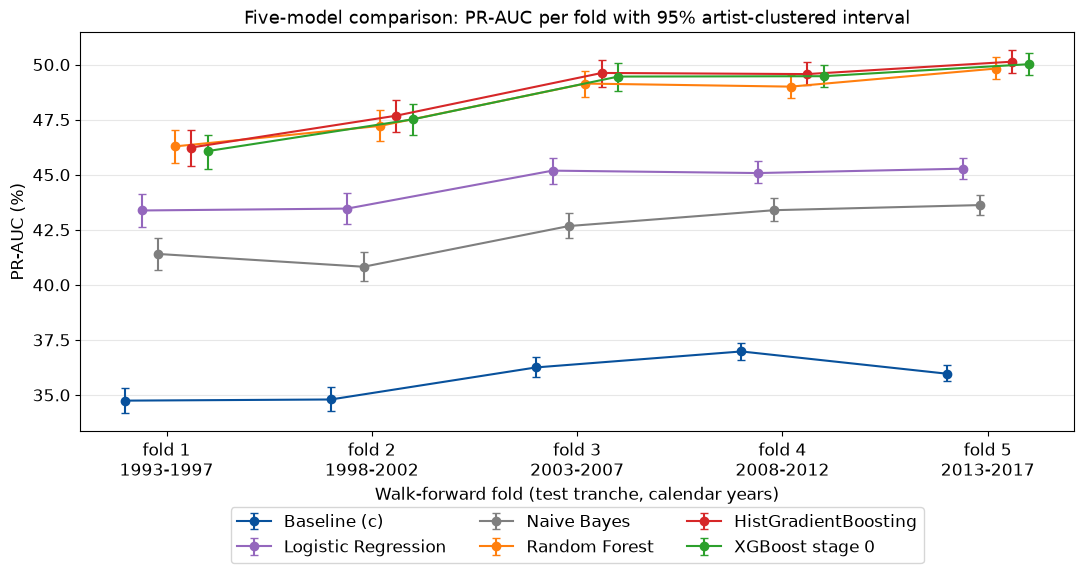

In [9]:
colors = {'Baseline (c)': '#08519c', 'Logistic Regression': '#9467bd', 'Naive Bayes': '#7f7f7f', 'Random Forest': '#ff7f0e', 'HistGradientBoosting': '#d62728', 'XGBoost stage 0': '#2ca02c'}  # one colour per model, (c) in the blue of what_design.ipynb section 7
fig, ax = plt.subplots(figsize=(11, 6))  # one line per model across the folds
for i, m in enumerate(order):  # reference first
    r = reports[m]  # per-fold report of the model
    yerr = [(r['pr_auc'] - r['pr_auc_lo']) * 100, (r['pr_auc_hi'] - r['pr_auc']) * 100]  # distance to the interval bounds, in points
    ax.errorbar(r.index + (i - 2.5) * 0.08, r['pr_auc'] * 100, yerr=yerr, fmt='o-', color=colors[m], capsize=3, markersize=6, label=m)  # line with markers and error bars, small offset so intervals do not overlap
ax.set_xticks(range(1, 6), labels=[f"fold {k}\n{years}" for k, years in reports['XGBoost stage 0']['test_years'].items()])  # fold number and test tranche
ax.set_xlabel('Walk-forward fold (test tranche, calendar years)')  # axis label
ax.set_ylabel('PR-AUC (%)')  # axis label with unit
ax.set_title('Five-model comparison: PR-AUC per fold with 95% artist-clustered interval')  # chart title
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3)  # model names below the plot, clear of the markers
ax.grid(axis='y', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

### Reading

Mean PR-AUC gain over baseline (c): HistGradientBoosting 12.90 points (101% of the XGBoost gain), XGBoost stage 0 12.76, Random Forest 12.55 (98%), Logistic Regression 8.73 (68%) and Naive Bayes 6.63 (52%). Every model is above (c) in 5 of 5 folds. The three tree models are tied in every fold (pairwise differences of at most 0.57 points, overlapping intervals, ROC-AUC within 0.0028). Logistic Regression and Naive Bayes are below the tree models in every fold with non-overlapping intervals; Naive Bayes is kept as a reference point. The gap between the linear model and the trees widens with the fold (2.86 / 4.22 / 4.44 / 4.49 / 4.86 points against HistGradientBoosting). Hypothesis, not tested: the extra gain of the trees comes from interactions and non-linear effects among the inputs.

### Decision

No model is selected among the three tree models by this comparison, since they are tied. XGBoost goes on to the staged tuning (random search, focused grid, manual refinement). The staged tuning of XGBoost follows the WHEN protocol, and the tie among the tree models is not used as a selection criterion: the choice is a design decision carried over from WHEN, not a finding of this comparison. No setting was changed after seeing a result, and the sealed holdout was not used. Logged in `docs/decisions.md`.

## 6. Holdout: the single final evaluation of stage 0

### Question: how does the final model, XGBoost stage 0, do on the sealed holdout, and what do the figures say in plain terms?

The holdout (artist-years of 2018-2022 whose label resolves by 2023) was evaluated once by `scripts/run_xgb_what_holdout.py`, with the thresholds and the report fixed beforehand in `docs/decisions.md` (entries "WHAT holdout label rule" and "WHAT threshold-metric report"). This notebook only reads the files that script saved under `results/holdout_what/`: nothing is refitted, rescored or recomputed here. Baseline (c) is the reference. PR-AUC stays the only selection and adoption metric; accuracy, precision, recall, F1 and lift are orientative, to show in plain terms how well the model predicts. A row is flagged as "new style" when its score is at or above the threshold (0.5, and 0.3067, the training positive rate).

In [10]:
from what_demo import read_holdout, accuracy_table, class_table, development_range, illustrative_cases, group_summary_lines  # readers of the saved holdout files, live in src/what_demo.py

holdout = read_holdout('../results/holdout_what')  # the five tables saved by scripts/run_xgb_what_holdout.py, nothing is recomputed
thresholds = sorted(holdout['threshold_summary']['threshold'].unique())  # the two fixed thresholds, read from the saved file
print(f"holdout rows: {int(holdout['headline']['rows'].iloc[0]):,} | artists: {int(holdout['headline']['artists'].iloc[0]):,} | thresholds: {thresholds}")  # size of the evaluated set

holdout rows: 143,228 | artists: 71,523 | thresholds: [np.float64(0.3067), np.float64(0.5)]


In [11]:
holdout['headline'].round(4)  # PR-AUC and ROC-AUC with 95% artist-clustered intervals (1,000 draws, seed 1), pooled over 2018-2022

,model,rows,artists,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,roc_auc_lo,roc_auc_hi
0,stage 0,143228,71523,0.3128,0.4986,0.4932,0.5036,0.6781,0.6748,0.6813
1,baseline (c),143228,71523,0.3128,0.3464,0.3429,0.3502,0.5586,0.5553,0.5620


In [12]:
holdout['by_year'].round(4)  # descriptive values per holdout year; 2023 has no rows because its labels resolve after 2023

,model,year,rows,positive_rate,pr_auc,roc_auc
0,stage 0,2018,32557,0.3134,0.5000,0.6803
1,stage 0,2019,32213,0.3155,0.4971,0.6718
2,stage 0,2020,31571,0.3144,0.4949,0.6726
3,stage 0,2021,26830,0.3065,0.4969,0.6834
4,stage 0,2022,20057,0.3136,0.5080,0.6868
5,baseline (c),2018,32557,0.3134,0.3470,0.5597
6,baseline (c),2019,32213,0.3155,0.3478,0.5555
7,baseline (c),2020,31571,0.3144,0.3451,0.5540
8,baseline (c),2021,26830,0.3065,0.3423,0.5607
9,baseline (c),2022,20057,0.3136,0.3510,0.5653


In [13]:
development_range('../results/trials/xgb_what_compare.csv', reports['Baseline (c)'], holdout['headline']).round(4)  # holdout value next to the lowest and highest value over the five validation folds, both read from saved files

,model,validation_pr_auc_min,validation_pr_auc_max,holdout_pr_auc,validation_roc_auc_min,validation_roc_auc_max,holdout_roc_auc
0,stage 0,0.4607,0.5002,0.4986,0.6677,0.6825,0.6781
1,baseline (c),0.3474,0.3698,0.3464,0.5633,0.5752,0.5586


In [14]:
accuracy_table(holdout['threshold_summary']).round(4)  # accuracy as its own column, next to the majority-class accuracy (always "no new style") and the holdout positive rate

,model,threshold,flagged_share,accuracy,majority_class_accuracy,holdout_positive_rate,note
0,stage 0,0.5000,0.0940,0.7065,0.6872,0.3128,
1,stage 0,0.3067,0.4852,0.6144,0.6872,0.3128,
2,baseline (c),0.5000,0.0000,0.6872,0.6872,0.3128,no rows flagged
3,baseline (c),0.3067,0.6519,0.4814,0.6872,0.3128,


In [15]:
class_table(holdout['threshold_by_class'])  # precision, recall, F1 and support per class at both thresholds; undefined where no row is flagged

,model,threshold,class,precision,recall,f1,support,note
0,stage 0,0.5,no new style,0.7172,0.9457,0.8158,98423,
1,stage 0,0.5,new style,0.6028,0.1811,0.2785,44805,
2,stage 0,0.3067,no new style,0.7929,0.594,0.6792,98423,
3,stage 0,0.3067,new style,0.425,0.6592,0.5168,44805,
4,baseline (c),0.5,no new style,0.6872,1.0,0.8146,98423,
5,baseline (c),0.5,new style,undefined,0.0,undefined,44805,no rows flagged
6,baseline (c),0.3067,no new style,0.7422,0.3759,0.4991,98423,
7,baseline (c),0.3067,new style,0.3422,0.7132,0.4625,44805,


In [16]:
holdout['top10_lift'].round(4)  # precision among the 10% of rows with the highest score, next to the positive rate and their ratio (lift); ties can select more than 10%

,model,score_cutoff,selected_share,selected_rows,precision_top,holdout_positive_rate,lift
0,stage 0,0.4943,0.1000,14323,0.5980,0.3128,1.9116
1,baseline (c),0.3636,0.1619,23183,0.3498,0.3128,1.1181


### Interpretation

**Ranking.** On 143,228 artist-years from 71,523 artists (positive rate 0.3128), stage 0 reaches PR-AUC 0.4986 [0.4932, 0.5036] and ROC-AUC 0.6781 [0.6748, 0.6813]. Baseline (c) reaches 0.3464 [0.3429, 0.3502] and 0.5586 [0.5553, 0.5620]. The intervals do not overlap: stage 0 is about 15 PR-AUC points and 12 ROC-AUC points above the reference. Year by year, stage 0 stays between 0.4949 and 0.5080 in PR-AUC and between 0.6718 and 0.6868 in ROC-AUC (2018-2022), with no trend.

**Against the validation folds.** The holdout values of stage 0 fall inside the range of the five validation folds (PR-AUC 0.4607 to 0.5002, ROC-AUC 0.6677 to 0.6825). Baseline (c) is slightly below its validation range (PR-AUC 0.3464 against 0.3474 to 0.3698, ROC-AUC 0.5586 against 0.5633 to 0.5752), so the gap to the reference is larger on the holdout than in any fold. No explanation is claimed for that. The signal is moderate and consistent with development.

**Accuracy is not informative here.** Always predicting "no new style" is right 68.7% of the time. At 0.5, stage 0 reaches 70.7% but flags only 9.4% of the artist-years. At 0.3067 it reaches 61.4%, below that reference, while flagging 48.5%. Baseline (c) never reaches 0.5, so it flags no row and its accuracy equals the reference; at 0.3067 it flags 65.2% and falls to 48.1%.

**Precision, recall and lift are the orientative figures.**
- At 0.5, 60.3% of the artist-years stage 0 flags do bring a new style (31.3% overall), but it finds only 18.1% of those that do (F1 0.2785).
- At 0.3067 it finds 65.9% of them, but only 42.5% of the flagged rows do bring one, so 57.5% are false alarms (F1 0.5168).
- Among the 10% of rows with the highest score, 59.8% bring a new style, a lift of 1.91 over the base rate. Baseline (c) selects 16.2% instead of 10% because its scores tie, with precision 0.3498 and lift 1.12.

In plain terms: the model puts artist-years that will add a new style ahead of those that will not, about twice as concentrated at the top as chance. It is a moderate signal, not case-by-case reliability.

**Limits.**
- The label rule favors short gaps, so the holdout positive rate (0.3128) differs from the training rate (0.3067).
- The effective window is 2018-2022, since 2023 labels resolve later.
- Calibration was not checked, and the thresholds are conventions, not tuned operating points.
- The threshold metrics have no intervals.
- Artists recur between train and holdout: the split is temporal, not by artist.
- Baseline (c) is coarse, with ties at its cell rates.
- There is one evaluation only, so no variability across fits is available.

Logged in `docs/decisions.md` (entry "WHAT final holdout evaluation of stage 0, single evaluation, now spent").

### Decision

The holdout was evaluated once and is spent: no re-run, no change and no further evaluation on it. XGBoost stage 0 stays as the WHAT final model, and nothing in this section changes a model, a metric or a threshold.

## 7. Illustrative cases: what do the saved scores look like for a few known artists?

### Question: do the holdout scores look sensible for some well-known artists and for artists drawn at random?

This section is a curiosity and a face-validity illustration, not methodology. It changes no model, metric or decision, and it is not evidence of accuracy: a handful of artist-years is anecdote, not validation. An artist-year is one artist in one year, and "new style: yes" means that the artist's next active year brought a style tag the artist had never used before (the WHAT target).

The artists were picked by fame and known stylistic reinvention, not by outcome, and the list was fixed before the scores were looked at: Bad Bunny, Taylor Swift, The Weeknd, Beyonce, Metallica and Coldplay, plus three artists drawn at random (seed 1) among those with at least 3 dated Works before 2018 and at least 3 eligible holdout rows. Kendrick Lamar, AC/DC and Iron Maiden are included with the caveat that each has a single eligible row. Rosalia is left out on purpose: two artist ids share the name, so the match is ambiguous.

The true label is shown whatever it is, failures included. The scores are the saved holdout scores of stage 0 from section 6: nothing is refitted or rescored here. A row is flagged when its score is at or above the threshold. No projection beyond 2023 appears here, since it would need a refit and belongs to the forecast.

In [17]:
cases = illustrative_cases('../results/holdout_what', '../data/processed/works_checkpoint.parquet', thresholds)  # saved stage 0 scores of the fixed artists, joined with the artist name, no score is recomputed
cases.round(4)  # one row per artist-year: score, true label, flags at both thresholds (score >= threshold) and the marker at the lower one

,group,artist,artist_id,year,stage0_score,new_style,flagged at 0.3067,flagged at 0.5,marker
0,"named, 1 eligible row",AC/DC,84752,2020,0.1312,no,no,no,correct no
1,random draw (seed 1),Abstract Division,2390402,2018,0.1631,no,no,no,correct no
2,random draw (seed 1),Abstract Division,2390402,2019,0.1694,no,no,no,correct no
3,random draw (seed 1),Abstract Division,2390402,2021,0.1337,no,no,no,correct no
4,named,Bad Bunny,5894905,2018,0.4310,no,yes,no,false alarm
5,named,Bad Bunny,5894905,2019,0.3300,yes,yes,no,hit
6,named,Bad Bunny,5894905,2020,0.4998,no,yes,no,false alarm
7,named,Bad Bunny,5894905,2021,0.3287,yes,yes,no,hit
8,named,Bad Bunny,5894905,2022,0.4975,yes,yes,no,hit
9,named,Beyoncé,52835,2021,0.3125,yes,yes,no,hit


In [18]:
for line in group_summary_lines(cases, min(thresholds)):  # one line per artist group at the training positive rate, then all fixed artists
    print(line)  # counts only, no percentages

named: 6 artists, 25 artist-years; 13 of 14 with a new style scored at or above 0.3067; 4 of 11 without one were flagged anyway
named, 1 eligible row: 3 artists, 3 artist-years; 0 of 0 with a new style scored at or above 0.3067; 1 of 3 without one were flagged anyway
random draw (seed 1): 3 artists, 11 artist-years; 1 of 1 with a new style scored at or above 0.3067; 3 of 10 without one were flagged anyway
all fixed artists: 12 artists, 39 artist-years; 14 of 15 with a new style scored at or above 0.3067; 8 of 24 without one were flagged anyway


### Interpretation

**What the cases show.** The 12 fixed artists give 39 artist-years, 15 of them with a new style (38.5%, above the 31.3% of the holdout). At the training positive rate (0.3067), the model scored 14 of those 15 at or above the threshold; the one miss is Coldplay in 2020 (score 0.203). It also flagged 8 of the 24 artist-years without a new style: Bad Bunny 2018 and 2020, Taylor Swift 2021, The Weeknd 2018, Habstrakt 2019, 2020 and 2022, and Kendrick Lamar 2018. Metallica, whose five rows all score between 0.14 and 0.21, has no new style in any of them, and the model agrees. At 0.5 only one of the 39 rows is flagged (Kendrick Lamar 2018, a false alarm), so the stricter threshold would show almost nothing in this list.

**By group.** Named artists: 13 of 14 with a new style flagged, 4 of 11 without one flagged anyway. Random draw: 1 of 1 and 3 of 10. The three artists with a single eligible row have no new style in their row, and one of the three (Kendrick Lamar) was flagged.

**Reading with care.**
- In this list, 14 of 22 flagged artist-years have a new style (64%), against 42.5% on the whole holdout at the same threshold, and 14 of 15 are found, against 65.9% on the whole holdout. The list looks better than the model does on average. That is not evidence of higher accuracy: the artists were picked for fame and visible reinvention, and active artists with long and varied histories get high scores from the history and volume features.
- A handful of artist-years is anecdote, not validation. One miss or one false alarm moves a percentage by several points.

**Known distortions.**
- Few rows per artist (1 to 5).
- The label rule favors short gaps.
- Undated Works are ignored by the features.
- The model reads counts, shares and timing of past styles and genres, not the music.
- A "new style" is a tag not used before by that artist in Discogs, so it also reflects how releases were tagged.

**Limits.** Calibration was not checked, and the thresholds are conventions. The true label is shown whatever it is, failures included. The list was fixed before the scores were seen, and Rosalia was left out for the ambiguity of her artist ids. There is no projection beyond 2023 here.

### Decision

None. This section is an illustration for a presentation audience. It changes no model, metric or decision, and it needs no entry in `docs/decisions.md`.

## 8. Live demo: what does stage 0 give for the last year of some well-known artists?

### Question: if the final model is applied to the last active year of a few famous artists, what does it say about the style of their next Work?

This section is a curiosity and a face-validity illustration, not methodology. It changes no model, metric or decision, and it is not evidence of accuracy. The artists were picked by fame, not by outcome, and the list is fixed: Bad Bunny, Beyonce, Taylor Swift, The Weeknd, Tyler, The Creator, Kendrick Lamar, Lorde, Tame Impala, Olivia Rodrigo, Sabrina Carpenter, Mitski, Metallica, Coldplay, Rihanna and Frank Ocean. Rosalia is left out on purpose: two artist ids share the name.

**Difference from the WHEN demo.** WHEN asked whether there will be a Work next year, so recency drove the ranking. WHAT asks whether the next Work, when it comes, introduces a style the artist has never used. The question is conditional on a next Work existing, and the model has no feature for the time elapsed up to today. So each artist is scored on the row of their last active year (no "live" construction), and no ordering by activity is expected.

**What the numbers mean.**
- Stage 0 is fitted once on the rows before 2018, as for the holdout evaluation, and scores the last active year of each artist. The scores come from `scripts/run_xgb_what_live.py` and are saved in `results/demo/what_live_scores.csv`; this notebook only reads that file.
- No label exists: the next Work either has not come or has not been loaded. The score is relative, not a forecast of which style will appear, and calibration was not checked.
- The last active year differs per artist, and a 2026 row has an understated `n_works_year` because the year is partial. The probability refers to any dated Work, singles and remixes included.
- Two reference points are shown next to the table: the training rate p (the share of artist-years before 2018 whose next Work introduced a new style) and the score of the 90th percentile of the holdout (the top 10% cutoff).
- The last two columns of the table are a cross-check: the saved holdout score of the artist's last holdout year, which is a different row from the live one.

In [19]:
from what_demo import read_live  # reader of the saved live scores, lives in src/what_demo.py

live, p, cutoff = read_live('../results/demo/what_live_scores.csv', '../results/holdout_what/top10_lift.csv')  # saved scores sorted by score, the training rate and the holdout top 10% cutoff
print(f"reference points: training rate p = {p:.4f} | holdout top 10% score cutoff (stage 0) = {cutoff:.4f}")  # the two reference points, both read from files
live.drop(columns='training_rate_p').round(4)  # one row per artist: last active year, inputs, live score and the saved score of the last holdout year

reference points: training rate p = 0.3067 | holdout top 10% score cutoff (stage 0) = 0.4943


,artist_id,artist,last_active_year,history_count,n_works_year,n_styles_seen,years_since_new_style,score,last_holdout_year,last_holdout_score
0,2013868,Frank Ocean,2020,18,4,11.0,0.0,0.5196,2019.0,0.3868
1,1967268,"Tyler, The Creator",2025,30,1,24.0,0.0,0.4957,2020.0,0.4313
2,5894905,Bad Bunny,2025,26,2,19.0,0.0,0.4922,2022.0,0.4975
3,4378284,Sabrina Carpenter,2026,41,1,14.0,2.0,0.4673,2022.0,0.4758
4,3317315,Lorde,2025,20,4,8.0,8.0,0.3945,2018.0,0.5820
5,2171152,The Weeknd,2026,60,1,32.0,1.0,0.3821,2022.0,0.4140
6,29735,Coldplay,2024,122,5,27.0,0.0,0.3792,2020.0,0.2029
7,1124645,Taylor Swift,2026,122,3,36.0,2.0,0.3751,2022.0,0.3071
8,52835,Beyoncé,2026,95,1,38.0,2.0,0.3618,2022.0,0.3346
9,7592689,Olivia Rodrigo,2026,23,6,15.0,2.0,0.3592,2022.0,0.5057


### Interpretation

**What the scores show.** The 15 scores range from 0.2501 (Metallica) to 0.5196 (Frank Ocean), with a median of 0.3751. Eleven of the 15 are at or above the training rate (0.3067) and four are below it (Kendrick Lamar 0.2934, Rihanna 0.2865, Mitski 0.2592, Metallica 0.2501). Two reach the holdout top 10% cutoff (0.4943): Frank Ocean (0.5196) and Tyler, The Creator (0.4957); Bad Bunny (0.4922) sits just under it. No order by activity is expected, and none is claimed: the table is sorted by score only, and the rows differ in the year they describe. They also differ in how much the model had to go on: six artists have a single Work in their last active year (Sabrina Carpenter, The Weeknd, Beyonce, Rihanna, Mitski and Tyler, The Creator), against 15 for Metallica.

**Artist resolution.** Each artist id was resolved by known release titles: for every id, a well-known release is in the cleaned Works table under that id (for example Blonde for Frank Ocean, Lemonade for Beyonce, Parachutes for Coldplay, Master of Puppets for Metallica), and the name in the table is the one in that table. Ten of the ids also appear in the WHEN demo (`backtesting_design.ipynb`, Step 8). Rosalia is left out because two artist ids share the name. All 15 artists have a last active year row with at least 3 dated Works before it, so none is missing.

**Known distortions.**
- The last active year differs per artist: 2020 (Frank Ocean), 2022 (Rihanna), 2024 (Coldplay, Kendrick Lamar), 2025 (four artists) and 2026 (seven artists). The model has no feature for the time elapsed up to today, so a row describes its own year and not the present.
- The 2026 rows have an understated `n_works_year`, since the year is partial (54,958 dated Works in 2026 against 117,600 in 2025 and 191,013 in 2020), and the recent years are still being loaded (2024: 134,900; 2025: 117,600), so counts of the latest years are low.
- The model is trained on rows before 2018, and these rows are 2020 to 2026.
- The score is conditional on a next Work existing, and it is relative: it ranks artist-years, it does not say which style will appear.

**Cross-check.** None of the 15 rows is a holdout row: the last active year of every artist falls after its last holdout row, or the artist has none, so the live score cannot be compared with a saved score of the same row. Rihanna has no holdout row. For the other 14, the saved score belongs to an earlier year (1 to 7 years before). The live score differs from it by at most 0.05 for six artists (Bad Bunny, Sabrina Carpenter, The Weeknd, Beyonce, Tame Impala and Metallica) and by 0.14 or more for four: Lorde (0.3945 against 0.5820 in 2018), Kendrick Lamar (0.2934 against 0.5141 in 2018), Olivia Rodrigo (0.3592 against 0.5057 in 2022) and Coldplay (0.3792 against 0.2029 in 2020). For those four, the change is more than half of the 0.27 between the lowest and the highest score of the list, so one score is a weak description of an artist. No explanation is claimed.

**Limits.**
- No label exists for these rows: the next Work either has not come or has not been loaded, so nothing here can be checked.
- Calibration was not checked, so the values are a relative ranking and not literal probabilities.
- The probability refers to any dated Discogs Work (singles, remixes and similar items included), not specifically an album.
- A handful of famous artists is anecdote, not validation.

### Decision

None. This section is an illustration for a presentation audience. It changes no model, metric or decision, and it needs no entry in `docs/decisions.md`.